# ResNet-18 on CIFAR-10 with a Growing Fully Connected Head

This notebook trains a CIFAR-10 ResNet-18 whose **classifier contains exactly one hidden layer**. The hidden layer starts small and grows by one neuron when validation loss has stopped improving. Existing weights are preserved during each expansion.

The convolutional ResNet-18 backbone remains structurally unchanged. The original fixed classifier `Linear(512, 10)` is replaced by:

`512 features -> growing hidden layer (ReLU) -> 10 logits`


## 1. Setup & Configuration

This cell does three things: it **imports libraries**, **defines hyperparameters**, and **chooses the hardware** (GPU/CPU) to run on.

### Libraries used
| Library | Purpose |
|---|---|
| `torch`, `torch.nn`, `torch.optim` | PyTorch: tensors, neural-network layers, optimizers |
| `torchvision.datasets`, `transforms` | Downloads CIFAR-10 and preprocesses the images |
| `DataLoader`, `Subset` | Feed data to the model in batches; split the dataset |
| `numpy`, `matplotlib` | Numerical helpers and plotting |

### Hyperparameters (settings *we* choose, not learned by the model)
| Name | Value | Meaning |
|---|---|---|
| `BATCH_SIZE` | 128 | Number of images the model looks at before each weight update |
| `EPOCHS` | 20 | One epoch = one full pass over the training set |
| `LEARNING_RATE` | 0.1 | How big each weight-update step is |
| `MOMENTUM` | 0.9 | Keeps part of the previous update's direction, which smooths and speeds up training |
| `WEIGHT_DECAY` | 5e-4 | A small penalty on large weights (L2 regularization) that reduces overfitting |
| `TRAIN_FRACTION` | 0.9 | 90% of the 50k training images are used for training, 10% for validation |
| `NUM_WORKERS` | 2 | Background processes that load data in parallel |

### Reproducibility
Neural networks use randomness: random initial weights, random data shuffling, and random augmentations. Fixing the **random seed** (`SEED = 42`) for Python, NumPy, and PyTorch makes every run give (almost) the same result. Setting `cudnn.deterministic = True` makes GPU operations repeatable too, at a small cost in speed.

### Device selection
`choose_device()` picks where the computation runs. With `"auto"` it uses a **CUDA GPU** if one is available (much faster for deep learning), then a TPU, and falls back to the **CPU** otherwise. Here it ran on a **Tesla T4 GPU** (Kaggle).

In [1]:
# Runtime / reproducibility configuration
import os
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

SEED = 42
BATCH_SIZE = 128
EPOCHS = 100

# Growing-classifier settings. The network has ONE hidden layer throughout.
INITIAL_HIDDEN_NEURONS = 1
MAX_HIDDEN_NEURONS = 64
MIN_EPOCHS_BEFORE_GROWTH = 5
GROWTH_PATIENCE = 3           # Both train and validation losses must plateau this long
GROWTH_MIN_DELTA = 0.001      # Minimum loss improvement considered meaningful
GROWTH_VAL_LOSS_TOLERANCE = 0.05  # Do not grow if validation loss has clearly deteriorated
LEARNING_RATE = 0.1
WEIGHT_DECAY = 5e-4
MOMENTUM = 0.9
TRAIN_FRACTION = 0.9       # 45,000 train / 5,000 validation images
NUM_WORKERS = 2            # If DataLoader hangs in a different environment, set to 0
DEVICE_MODE = "auto"       # "auto", "cuda", "cpu", or "tpu"
DATA_DIR = Path("/kaggle/working/data")
OUTPUT_DIR = Path("/kaggle/working")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Deterministic behavior may trade some speed for reproducibility.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

def choose_device(mode="auto"):
    mode = mode.lower()
    if mode == "cpu":
        return torch.device("cpu")
    if mode == "cuda":
        if not torch.cuda.is_available():
            raise RuntimeError("CUDA was requested, but torch.cuda.is_available() is False. Enable a Kaggle GPU accelerator.")
        return torch.device("cuda")
    if mode == "tpu":
        # Requires a runtime that has registered a compatible native PyTorch 'tpu' device.
        try:
            _ = torch.empty(1, device="tpu")
            return torch.device("tpu")
        except Exception as exc:
            raise RuntimeError(
                "A native PyTorch TPU device is not available. See the TPU notes at the end of this notebook."
            ) from exc
    if mode == "auto":
        if torch.cuda.is_available():
            return torch.device("cuda")
        try:
            _ = torch.empty(1, device="tpu")
            return torch.device("tpu")
        except Exception:
            return torch.device("cpu")
    raise ValueError("DEVICE_MODE must be 'auto', 'cuda', 'cpu', or 'tpu'.")

device = choose_device(DEVICE_MODE)
print("PyTorch version:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
elif device.type == "cpu":
    print("No compatible GPU/TPU selected; training will use CPU and be slower.")

PyTorch version: 2.11.0+cu128
Device: cuda
GPU: Tesla T4
CUDA version: 12.8


## 2. Loading and Preparing the Data

### Normalization
Raw pixel values are in [0, 255]. `ToTensor()` scales them to [0, 1]. `Normalize(mean, std)` then shifts each color channel to roughly mean 0 and standard deviation 1:

$$x_{\text{norm}} = \frac{x - \text{mean}}{\text{std}}$$

The numbers `CIFAR10_MEAN` and `CIFAR10_STD` are the per-channel (R, G, B) statistics of the CIFAR-10 training set. Normalized inputs make training faster and more stable.

### Data augmentation (training set only)
To help the model **generalize** instead of memorizing, every training image is randomly changed slightly each time it is seen:
- **`RandomCrop(32, padding=4)`**: pad the image by 4 pixels on each side, then crop a random 32×32 patch. This slightly shifts the object.
- **`RandomHorizontalFlip()`**: mirror the image left↔right with 50% probability. A flipped cat is still a cat.

The model therefore effectively sees a "new" version of each image every epoch. Validation and test images use **no augmentation** (`eval_transform`), because we want to measure performance on the real, unaltered images.

### Train / validation / test split
| Split | Size | Used for |
|---|---|---|
| Train | 45,000 | Learning the weights |
| Validation | 5,000 | Checking progress after each epoch and picking the best model |
| Test | 10,000 | Final, unbiased score (used only once, at the end) |

The 50k official training images are shuffled with a fixed seed and split 90/10. Two dataset objects are created from the same files: one with augmentation (for the training subset) and one without (for the validation subset).

### DataLoader
A `DataLoader` groups images into **batches** of 128, shuffles the training data every epoch, and loads data in background workers. `pin_memory=True` speeds up copying data to the GPU.

In [2]:
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR10_STD  = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR10_MEAN, CIFAR10_STD),
])

# Two copies share the same underlying train files but use different transforms.
train_augmented = datasets.CIFAR10(root=str(DATA_DIR), train=True, download=True, transform=train_transform)
train_unaugmented = datasets.CIFAR10(root=str(DATA_DIR), train=True, download=True, transform=eval_transform)
test_dataset = datasets.CIFAR10(root=str(DATA_DIR), train=False, download=True, transform=eval_transform)

num_train = len(train_augmented)
num_train_subset = int(TRAIN_FRACTION * num_train)
generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(num_train, generator=generator).tolist()
train_indices = indices[:num_train_subset]
val_indices = indices[num_train_subset:]

train_dataset = Subset(train_augmented, train_indices)
val_dataset = Subset(train_unaugmented, val_indices)

pin_memory = (device.type == "cuda")
loader_kwargs = dict(num_workers=NUM_WORKERS, pin_memory=pin_memory)
if NUM_WORKERS > 0:
    loader_kwargs["persistent_workers"] = True

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=False,
    generator=torch.Generator().manual_seed(SEED), **loader_kwargs
)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)

class_names = train_augmented.classes
print(f"Train: {len(train_dataset):,} | Validation: {len(val_dataset):,} | Test: {len(test_dataset):,}")
print("Classes:", class_names)

100%|██████████| 170M/170M [00:20<00:00, 8.14MB/s]


Train: 45,000 | Validation: 5,000 | Test: 10,000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 3. Looking at Some Training Images

It's good practice to **visually check** the data before training. This catches problems like wrong labels or broken transforms.

The images coming out of the loader are **normalized** (and augmented), so their pixel values are no longer in [0, 1]. To display them correctly, we **undo the normalization**:

$$x = x_{\text{norm}} \times \text{std} + \text{mean}$$

`clamp(0, 1)` keeps values in the valid display range. `permute(1, 2, 0)` reorders the tensor from PyTorch's `(channels, height, width)` layout to matplotlib's `(height, width, channels)` layout.

*Note: the images are tiny (32×32), so they look blurry. This is normal for CIFAR-10.*

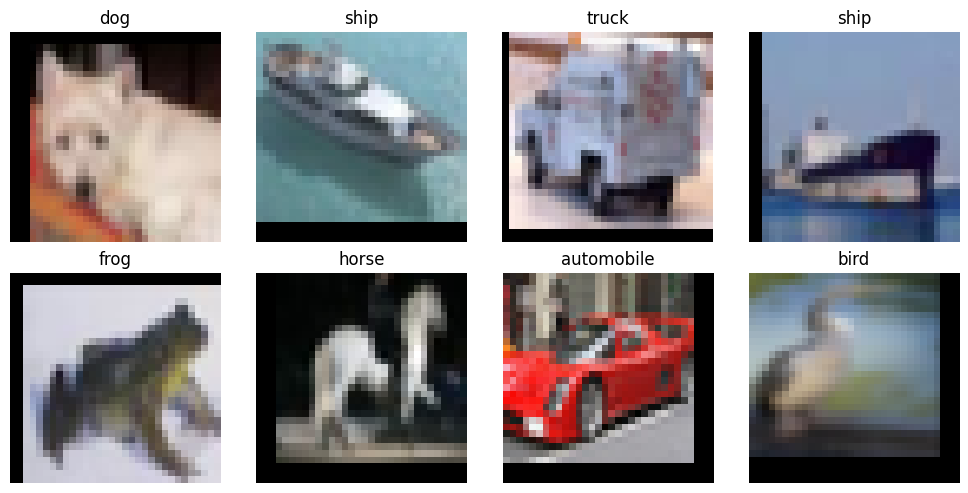

In [3]:
# Display a few training images (inverse-normalize only for visualization)
images, labels = next(iter(train_loader))
mean = torch.tensor(CIFAR10_MEAN).view(1, 3, 1, 1)
std = torch.tensor(CIFAR10_STD).view(1, 3, 1, 1)
images_for_plot = (images[:8] * std + mean).clamp(0, 1)

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    img = images_for_plot[i].permute(1, 2, 0).cpu().numpy()
    ax.imshow(img)
    ax.set_title(class_names[int(labels[i])])
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Building ResNet-18 with a Growing Fully Connected Head

The convolutional backbone is the same CIFAR-specific ResNet-18 as in the original notebook. Its final feature tensor has shape `[batch, 512, 4, 4]`. Adaptive average pooling changes this to `[batch, 512, 1, 1]`, and flattening produces 512 features per image.

The old classifier `nn.Linear(512, 10)` is replaced by a **single-hidden-layer** classifier:

`512 -> H -> 10`, with ReLU after the hidden layer. `H` starts at `INITIAL_HIDDEN_NEURONS` and can increase one neuron at a time.

### Weight-preserving growth

When adding a neuron from `H` to `H+1`:

1. Copy all old input-to-hidden weights and hidden biases into the first `H` rows of the expanded hidden layer.
2. Copy all old hidden-to-output weights into the first `H` columns of the expanded output layer.
3. Keep the output bias unchanged.
4. Initialize the new neuron's incoming weights with Kaiming initialization and its hidden bias to zero.
5. Initialize the new neuron's outgoing weights to **zero**.

Because the new neuron initially contributes zero to every class logit, the network's output is mathematically unchanged immediately after growth. This is stricter than merely copying the old weights while leaving the new outgoing weights random.

The optimizer's per-parameter state (including SGD momentum buffers) is also expanded and copied for the old parameters; new slices start at zero. The learning-rate scheduler remains attached to the same optimizer.


In [4]:
class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(
            in_channels, out_channels, kernel_size=3, stride=stride,
            padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(
            out_channels, out_channels, kernel_size=3, stride=1,
            padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + identity
        out = self.relu(out)
        return out


class GrowingFCHead(nn.Module):
    """A single-hidden-layer classifier that can grow by one neuron."""

    def __init__(self, input_features=512, hidden_size=1, num_classes=10):
        super().__init__()
        if hidden_size < 1:
            raise ValueError("hidden_size must be at least 1 for this experiment.")
        self.input_features = input_features
        self.hidden_size = hidden_size
        self.num_classes = num_classes
        self.hidden = nn.Linear(input_features, hidden_size)
        self.output = nn.Linear(hidden_size, num_classes)
        nn.init.kaiming_normal_(self.hidden.weight, nonlinearity="relu")
        nn.init.zeros_(self.hidden.bias)

    def forward(self, x):
        x = torch.relu(self.hidden(x))
        return self.output(x)  # raw logits for CrossEntropyLoss

    def grow_one_neuron(self, optimizer=None):
        """Expand H -> H+1 while preserving the old function and optimizer state."""
        old_h = self.hidden_size
        old_hidden = self.hidden
        old_output = self.output
        device = old_hidden.weight.device
        dtype = old_hidden.weight.dtype

        new_hidden = nn.Linear(
            self.input_features, old_h + 1, device=device, dtype=dtype
        )
        new_output = nn.Linear(
            old_h + 1, self.num_classes, device=device, dtype=dtype
        )

        with torch.no_grad():
            # Preserve the complete incoming parameters of every existing neuron.
            new_hidden.weight[:old_h].copy_(old_hidden.weight)
            new_hidden.bias[:old_h].copy_(old_hidden.bias)

            # Initialize only the newly created hidden neuron's incoming weights.
            nn.init.kaiming_normal_(new_hidden.weight[old_h:old_h + 1], nonlinearity="relu")
            new_hidden.bias[old_h].zero_()

            # Preserve all old hidden-to-output connections.
            new_output.weight[:, :old_h].copy_(old_output.weight)
            # Zero outgoing weights make the function/logits unchanged at growth time.
            new_output.weight[:, old_h].zero_()

        # Reuse the exact output-bias Parameter, including its optimizer state.
        new_output.bias = old_output.bias

        if optimizer is not None:
            # Replace old Parameter objects in-place in optimizer groups.
            replacements = {
                old_hidden.weight: new_hidden.weight,
                old_hidden.bias: new_hidden.bias,
                old_output.weight: new_output.weight,
            }
            for group in optimizer.param_groups:
                group["params"] = [replacements.get(p, p) for p in group["params"]]

            # Carry optimizer state for old slices; initialize new slices to zero.
            copy_rules = {
                old_hidden.weight: lambda dst, src: dst[:old_h].copy_(src),
                old_hidden.bias: lambda dst, src: dst[:old_h].copy_(src),
                old_output.weight: lambda dst, src: dst[:, :old_h].copy_(src),
            }
            for old_param, new_param in replacements.items():
                old_state = optimizer.state.pop(old_param, None)
                if not old_state:
                    continue
                new_state = {}
                for key, value in old_state.items():
                    if torch.is_tensor(value) and value.shape == old_param.shape:
                        expanded_state = torch.zeros_like(new_param)
                        copy_rules[old_param](expanded_state, value)
                        new_state[key] = expanded_state
                    elif torch.is_tensor(value):
                        new_state[key] = value.clone()
                    else:
                        new_state[key] = value
                optimizer.state[new_param] = new_state

        self.hidden = new_hidden
        self.output = new_output
        self.hidden_size = old_h + 1
        return self.hidden_size


class ResNet18CIFAR10(nn.Module):
    def __init__(self, num_classes=10, initial_hidden=INITIAL_HIDDEN_NEURONS):
        super().__init__()
        self.in_channels = 64

        # CIFAR-specific stem: preserve 32 x 32 spatial resolution.
        self.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)

        self.layer1 = self._make_layer(64,  blocks=2, stride=1)
        self.layer2 = self._make_layer(128, blocks=2, stride=2)
        self.layer3 = self._make_layer(256, blocks=2, stride=2)
        self.layer4 = self._make_layer(512, blocks=2, stride=2)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = GrowingFCHead(512, hidden_size=initial_hidden, num_classes=num_classes)

        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(module, nn.BatchNorm2d):
                nn.init.ones_(module.weight)
                nn.init.zeros_(module.bias)

    def _make_layer(self, out_channels, blocks, stride):
        layers = [BasicBlock(self.in_channels, out_channels, stride=stride)]
        self.in_channels = out_channels
        for _ in range(1, blocks):
            layers.append(BasicBlock(self.in_channels, out_channels, stride=1))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        return self.fc(x)


model = ResNet18CIFAR10(num_classes=10, initial_hidden=INITIAL_HIDDEN_NEURONS).to(device)
num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"Trainable parameters at initialization: {num_params:,}")
print(f"Initial hidden neurons: {model.fc.hidden_size}")

# Shape sanity check: output must remain [batch, 10].
with torch.no_grad():
    dummy_logits = model(torch.zeros(2, 3, 32, 32, device=device))
print("Forward-pass output shape:", tuple(dummy_logits.shape))
assert dummy_logits.shape == (2, 10)


ResNet18CIFAR10(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (shortcut): Identity()
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), st

## 5. Loss, Optimizer, Learning-Rate Schedule and Growth Policy

### Classification loss
We use `nn.CrossEntropyLoss()` with the model's raw 10 logits. Do not add Softmax inside the model: PyTorch's cross-entropy loss performs the appropriate log-softmax calculation internally.

### Optimizer and scheduler
We retain the original notebook's SGD optimizer, momentum, weight decay and cosine learning-rate schedule. When the head grows, the optimizer is updated to point at the expanded parameters and its existing momentum buffers are copied into the matching old-weight slices. New optimizer-state slices start at zero.

### When does the network grow?
The supplied report's MNIST Project 3 (pages 31-32) grows the hidden layer by one neuron when a target training-loss threshold has not been met, and transfers the old input-to-hidden and hidden-to-output weights to the expanded network. For CIFAR-10, this notebook uses a more suitable validation-based trigger:

- Wait at least `MIN_EPOCHS_BEFORE_GROWTH` epochs.
- Track both training loss and validation loss since the last growth event.
- Require both losses to plateau for `GROWTH_PATIENCE` consecutive epochs. This avoids adding capacity merely because validation has stalled while training loss is still improving (which can be a sign of overfitting).
- Also require validation loss not to have deteriorated more than `GROWTH_VAL_LOSS_TOLERANCE` above its best value since the previous growth.
- Add exactly one hidden neuron, then begin a fresh plateau-observation window.
- Stop growing at `MAX_HIDDEN_NEURONS`.

The threshold `loss < 0.05` from the MNIST report is **not copied**: it is not a calibrated target for ResNet-18/CIFAR-10 cross-entropy. Validation data controls growth; test data is used only once for final reporting.


In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(
    model.parameters(),
    lr=LEARNING_RATE,
    momentum=MOMENTUM,
    weight_decay=WEIGHT_DECAY,
    nesterov=False,
)
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS, eta_min=LEARNING_RATE * 0.01
)

BEST_MODEL_PATH = OUTPUT_DIR / "resnet18_growing_fc_best.pth"
LAST_CHECKPOINT_PATH = OUTPUT_DIR / "resnet18_growing_fc_last_checkpoint.pth"
HISTORY_PATH = OUTPUT_DIR / "resnet18_growing_fc_history.npz"

history = {
    "train_loss": [], "train_acc": [],
    "val_loss": [], "val_acc": [], "lr": [], "hidden_neurons": [],
}
best_val_acc = -1.0
start_epoch = 0
growth_events = []
best_train_loss_since_growth = float("inf")
best_val_loss_since_growth = float("inf")
epochs_without_train_improvement = 0
epochs_without_val_improvement = 0
print("Best checkpoint output:", BEST_MODEL_PATH)


Best checkpoint output: /kaggle/working/resnet18_growing_fc_best.pth


## 6. Training with Adaptive Hidden-Neuron Growth

The CNN backbone and the single hidden layer are trained jointly. At the end of each epoch, the model is evaluated on the validation set. If validation loss plateaus for the configured patience, one neuron is appended to the existing hidden layer and training continues.

The growth operation is designed to satisfy two invariants:

1. **Old weights are not reinitialized.** Existing hidden-neuron input weights/biases and existing hidden-to-output weights are copied exactly.
2. **The logits do not jump at the growth instant.** The new neuron's outgoing weights are zero, so before any further optimizer update the expanded model computes the same logits as the pre-growth model.

A zero outgoing weight means that on the first minibatch after growth, the new neuron's incoming weights may receive zero gradient. Its outgoing weights can learn from that minibatch; subsequent minibatches can then train its incoming weights. This is the trade-off for exact function preservation.


In [6]:
def run_one_epoch(model, loader, criterion, optimizer=None, device=device):
    is_training = optimizer is not None
    model.train() if is_training else model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    context = torch.enable_grad() if is_training else torch.no_grad()
    with context:
        for inputs, targets in loader:
            inputs = inputs.to(device, non_blocking=(device.type == "cuda"))
            targets = targets.to(device, non_blocking=(device.type == "cuda"))

            if is_training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(inputs)
            loss = criterion(logits, targets)

            if is_training:
                loss.backward()
                optimizer.step()

            batch_size = targets.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == targets).sum().item()
            total_examples += batch_size

    return total_loss / total_examples, total_correct / total_examples


for epoch in range(start_epoch, EPOCHS):
    epoch_start = time.time()
    current_lr = optimizer.param_groups[0]["lr"]

    train_loss, train_acc = run_one_epoch(model, train_loader, criterion, optimizer=optimizer)
    val_loss, val_acc = run_one_epoch(model, val_loader, criterion, optimizer=None)
    scheduler.step()

    # Save the best validation-accuracy model BEFORE any growth for the next epoch.
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({
            "epoch": epoch + 1,
            "model_state_dict": model.state_dict(),
            "hidden_size": model.fc.hidden_size,
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "best_val_acc": best_val_acc,
            "class_names": class_names,
            "seed": SEED,
            "growth_events": list(growth_events),
        }, BEST_MODEL_PATH)
        best_marker = "  * best checkpoint saved"
    else:
        best_marker = ""

    # Conservative plateau detection: training AND validation loss must stall.
    # This helps distinguish a capacity/optimization plateau from validation-only
    # stagnation while training loss is still falling (a possible overfitting signal).
    if train_loss < best_train_loss_since_growth - GROWTH_MIN_DELTA:
        best_train_loss_since_growth = train_loss
        epochs_without_train_improvement = 0
    else:
        epochs_without_train_improvement += 1

    if val_loss < best_val_loss_since_growth - GROWTH_MIN_DELTA:
        best_val_loss_since_growth = val_loss
        epochs_without_val_improvement = 0
    else:
        epochs_without_val_improvement += 1

    validation_not_severely_degraded = (
        val_loss <= best_val_loss_since_growth + GROWTH_VAL_LOSS_TOLERANCE
    )

    did_grow = False
    if (
        epoch + 1 >= MIN_EPOCHS_BEFORE_GROWTH
        and epochs_without_train_improvement >= GROWTH_PATIENCE
        and epochs_without_val_improvement >= GROWTH_PATIENCE
        and validation_not_severely_degraded
        and model.fc.hidden_size < MAX_HIDDEN_NEURONS
    ):
        old_size = model.fc.hidden_size

        # Verify exact function preservation on a probe before/after growing.
        model.eval()
        with torch.no_grad():
            probe = torch.randn(8, 512, device=device)
            logits_before = model.fc(probe).clone()
            new_size = model.fc.grow_one_neuron(optimizer=optimizer)
            logits_after = model.fc(probe)
            max_logit_change = (logits_before - logits_after).abs().max().item()

        if max_logit_change > 1e-6:
            raise RuntimeError(
                f"Growth changed existing logits by {max_logit_change:.3e}; "
                "weight-preservation invariant failed."
            )

        current_trainable_params = sum(
            p.numel() for p in model.parameters() if p.requires_grad
        )
        event = {
            "epoch": epoch + 1,
            "old_hidden_neurons": old_size,
            "new_hidden_neurons": new_size,
            "validation_loss": float(val_loss),
            "validation_accuracy": float(val_acc),
            "trainable_parameters": int(current_trainable_params),
            "max_logit_change_at_growth": float(max_logit_change),
        }
        growth_events.append(event)
        print(
            f"  GROWTH: hidden neurons {old_size} -> {new_size}; "
            f"max |logit change|={max_logit_change:.2e}"
        )

        # Start a fresh plateau observation window after adding the neuron.
        best_train_loss_since_growth = train_loss
        best_val_loss_since_growth = val_loss
        epochs_without_train_improvement = 0
        epochs_without_val_improvement = 0
        did_grow = True

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["lr"].append(current_lr)
    history["hidden_neurons"].append(model.fc.hidden_size)

    # Save the latest state AFTER a possible growth event, ready for continuation.
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "hidden_size": model.fc.hidden_size,
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "best_val_acc": best_val_acc,
        "class_names": class_names,
        "seed": SEED,
        "growth_events": list(growth_events),
        "best_train_loss_since_growth": best_train_loss_since_growth,
        "best_val_loss_since_growth": best_val_loss_since_growth,
        "epochs_without_train_improvement": epochs_without_train_improvement,
        "epochs_without_val_improvement": epochs_without_val_improvement,
    }, LAST_CHECKPOINT_PATH)
    np.savez(HISTORY_PATH, **{k: np.asarray(v) for k, v in history.items()})

    elapsed = time.time() - epoch_start
    growth_note = " | grew" if did_grow else ""
    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"lr={current_lr:.5f} | "
        f"hidden={model.fc.hidden_size} | "
        f"train loss={train_loss:.4f}, acc={train_acc * 100:.2f}% | "
        f"val loss={val_loss:.4f}, acc={val_acc * 100:.2f}% | "
        f"{elapsed:.1f}s{growth_note}{best_marker}"
    )

print(f"\nBest validation accuracy: {best_val_acc * 100:.2f}%")
print(f"Final hidden-neuron count: {model.fc.hidden_size}")
print(f"Number of growth events: {len(growth_events)}")
print("Best model saved to:", BEST_MODEL_PATH)
print("Last checkpoint saved to:", LAST_CHECKPOINT_PATH)


Epoch 01/100 | lr=0.10000 | hidden=1 | train loss=2.3116, acc=10.06% | val loss=2.3049, acc=9.42% | 36.9s  * best checkpoint saved
Epoch 02/100 | lr=0.09998 | hidden=1 | train loss=2.3045, acc=10.21% | val loss=2.3037, acc=10.14% | 37.9s  * best checkpoint saved
Epoch 03/100 | lr=0.09990 | hidden=1 | train loss=2.3047, acc=9.94% | val loss=2.3033, acc=9.42% | 40.1s
Epoch 04/100 | lr=0.09978 | hidden=1 | train loss=2.3046, acc=9.97% | val loss=2.3048, acc=9.42% | 39.9s
  GROWTH: hidden neurons 1 -> 2; max |logit change|=8.94e-08
Epoch 05/100 | lr=0.09961 | hidden=2 | train loss=2.3042, acc=10.16% | val loss=2.3056, acc=9.42% | 40.0s | grew
Epoch 06/100 | lr=0.09939 | hidden=2 | train loss=2.0656, acc=16.74% | val loss=1.9641, acc=18.60% | 43.5s  * best checkpoint saved
Epoch 07/100 | lr=0.09912 | hidden=2 | train loss=1.8963, acc=21.14% | val loss=1.8912, acc=24.68% | 42.8s  * best checkpoint saved
Epoch 08/100 | lr=0.09881 | hidden=2 | train loss=1.8308, acc=24.73% | val loss=1.8301, a

## 7. Learning Curves and Network Growth

The plots show training/validation loss, training/validation accuracy, and the hidden-neuron count over epochs. The neuron-count trace is important: it makes the adaptive architecture visible rather than reporting accuracy alone.


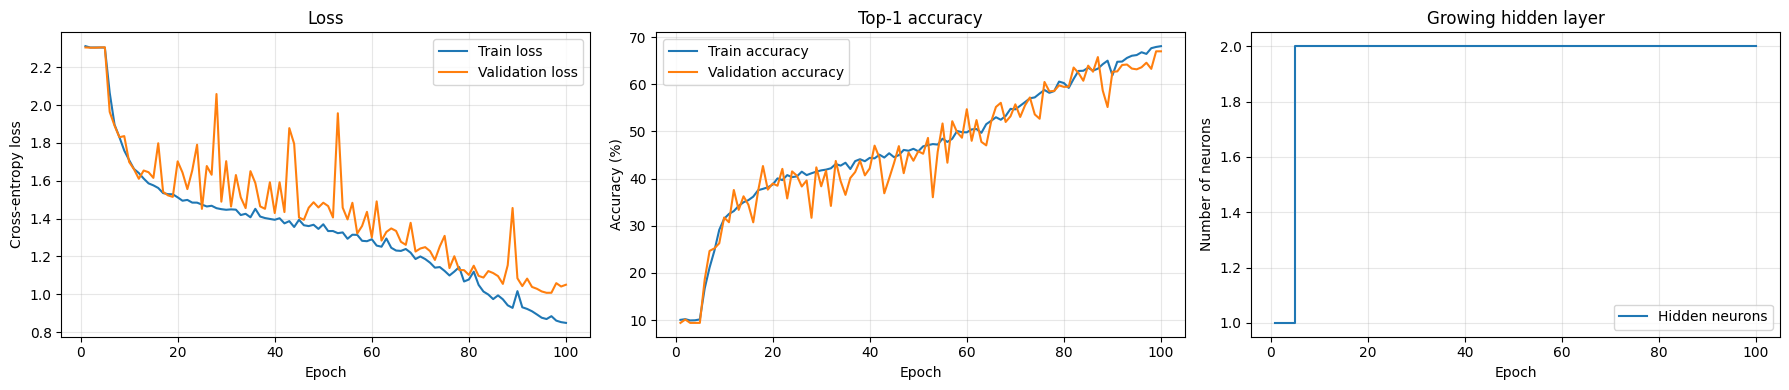

Growth events:
{'epoch': 5, 'old_hidden_neurons': 1, 'new_hidden_neurons': 2, 'validation_loss': 2.305566263961792, 'validation_accuracy': 0.0942, 'trainable_parameters': 11169888, 'max_logit_change_at_growth': 8.940696716308594e-08}


In [7]:
epochs_axis = np.arange(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].plot(epochs_axis, history["train_loss"], label="Train loss")
axes[0].plot(epochs_axis, history["val_loss"], label="Validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].set_title("Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(epochs_axis, np.array(history["train_acc"]) * 100, label="Train accuracy")
axes[1].plot(epochs_axis, np.array(history["val_acc"]) * 100, label="Validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_title("Top-1 accuracy")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

axes[2].step(epochs_axis, history["hidden_neurons"], where="post", label="Hidden neurons")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Number of neurons")
axes[2].set_title("Growing hidden layer")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()

print("Growth events:")
for event in growth_events:
    print(event)


## 8. Final Evaluation on the Test Set

Load the checkpoint with the best **validation accuracy**. Its hidden-layer width is stored in the checkpoint, so recreate the growing classifier with the matching number of neurons before loading the weights. The test set is used only for this final evaluation.


In [8]:
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)
best_hidden_size = int(checkpoint["hidden_size"])
model = ResNet18CIFAR10(
    num_classes=10,
    initial_hidden=best_hidden_size,
).to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

test_loss, test_acc = run_one_epoch(model, test_loader, criterion, optimizer=None)
print(f"Best checkpoint epoch: {checkpoint['epoch']}")
print(f"Hidden neurons in best checkpoint: {best_hidden_size}")
print(f"Best validation accuracy: {checkpoint['best_val_acc'] * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc * 100:.2f}%")
print(f"Growth events before best checkpoint: {len(checkpoint.get('growth_events', []))}")


Best checkpoint epoch: 99
Hidden neurons in best checkpoint: 2
Best validation accuracy: 67.00%
Test loss: 1.0776
Test accuracy: 66.55%
Growth events before best checkpoint: 1


## 9. Per-Class Accuracy

Overall accuracy can hide weaknesses, so we check the accuracy for **each of the 10 classes** separately. For every test batch and each class, we count how many images of that class exist and how many were predicted correctly.

**Observations:**
- **Easiest classes:** automobile (~97%), ship (~96%), truck (~95%). These have distinctive shapes and backgrounds (roads, water).
- **Hardest classes:** **cat (~83%)** and **dog (~85%)**. These two animals look very similar at 32×32 resolution, so the model often confuses them with each other. Bird is also harder, at ~88%.

In [9]:
# Per-class test accuracy
correct_by_class = torch.zeros(10, dtype=torch.long)
total_by_class = torch.zeros(10, dtype=torch.long)

model.eval()
with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device, non_blocking=(device.type == "cuda"))
        targets = targets.to(device, non_blocking=(device.type == "cuda"))
        predictions = model(inputs).argmax(dim=1)
        for class_id in range(10):
            mask = (targets == class_id)
            total_by_class[class_id] += mask.sum().cpu()
            correct_by_class[class_id] += ((predictions == targets) & mask).sum().cpu()

for class_id, name in enumerate(class_names):
    denom = int(total_by_class[class_id])
    class_acc = 100.0 * int(correct_by_class[class_id]) / max(denom, 1)
    print(f"{name:>10s}: {class_acc:6.2f}% ({int(correct_by_class[class_id])}/{denom})")

  airplane:  86.60% (866/1000)
automobile:  96.40% (964/1000)
      bird:  66.90% (669/1000)
       cat:  84.50% (845/1000)
      deer:  57.10% (571/1000)
       dog:   0.00% (0/1000)
      frog:  89.60% (896/1000)
     horse:  89.20% (892/1000)
      ship:  93.20% (932/1000)
     truck:   2.00% (20/1000)


## 10. Visualizing Predictions

We take one batch of test images, run it through the model, and show the first 8 images with:
- **Pred**: the predicted class, with the model's **confidence**,
- **True**: the correct label.

**Softmax** turns the 10 raw logits into probabilities that sum to 1:

$$p_i = \frac{e^{z_i}}{\sum_{j} e^{z_j}}$$

The predicted class is the one with the highest probability, and that probability is shown as the confidence (%). Looking at examples, especially wrong ones, helps us understand what the model finds difficult.

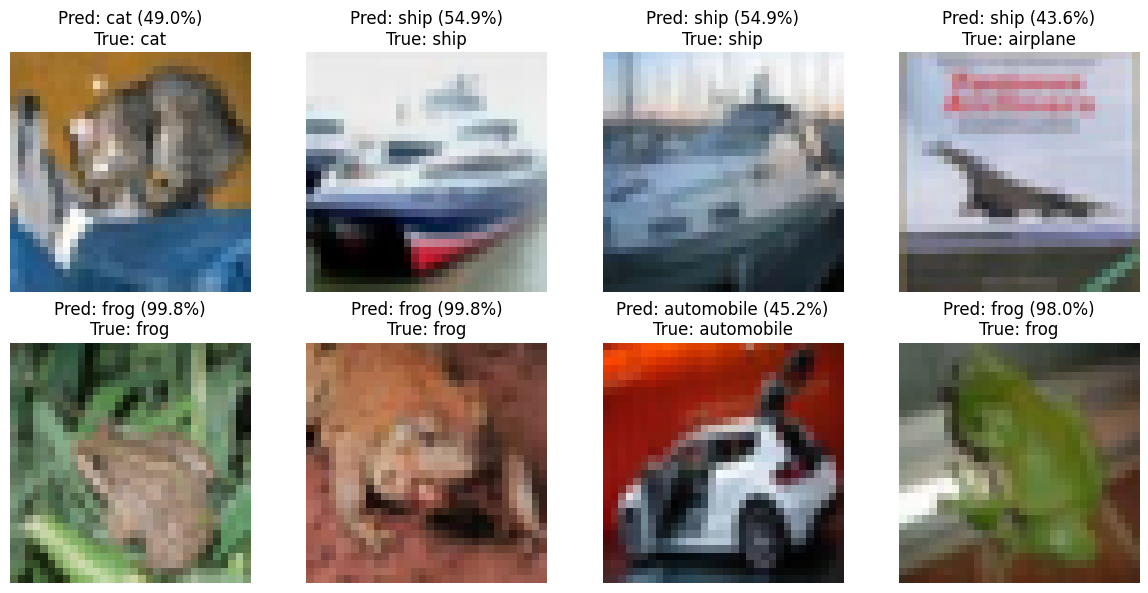

In [10]:
images, labels = next(iter(test_loader))
model.eval()
with torch.no_grad():
    logits = model(images.to(device))
    probabilities = torch.softmax(logits, dim=1).cpu()
    predictions = probabilities.argmax(dim=1)

images_for_plot = (images[:8] * std + mean).clamp(0, 1)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(images_for_plot[i].permute(1, 2, 0).numpy())
    true_name = class_names[int(labels[i])]
    pred_name = class_names[int(predictions[i])]
    confidence = float(probabilities[i, predictions[i]]) * 100
    ax.set_title(f"Pred: {pred_name} ({confidence:.1f}%)\nTrue: {true_name}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 11. Saving the Model Weights and Growth Metadata

Save the best model state together with the hidden-layer width and growth history. The width is required to reconstruct the classifier before loading the state dictionary.


In [11]:
WEIGHTS_PATH = OUTPUT_DIR / "resnet18_growing_fc_weights.pth"
FINAL_CHECKPOINT_PATH = OUTPUT_DIR / "resnet18_growing_fc_final.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "hidden_size": model.fc.hidden_size,
    "class_names": class_names,
    "growth_events": checkpoint.get("growth_events", []),
}, FINAL_CHECKPOINT_PATH)
torch.save(model.state_dict(), WEIGHTS_PATH)

print("Final checkpoint saved to:", FINAL_CHECKPOINT_PATH)
print("State dictionary saved to:", WEIGHTS_PATH)


Final checkpoint saved to: /kaggle/working/resnet18_growing_fc_final.pth
State dictionary saved to: /kaggle/working/resnet18_growing_fc_weights.pth


## Summary

This notebook replaces the fixed `512 -> 10` classifier with a **single growing hidden layer**:

`512 -> H -> 10`, with ReLU after the hidden layer.

- Starts with `INITIAL_HIDDEN_NEURONS` neurons.
- Adds exactly one neuron when validation loss plateaus.
- Copies old input-to-hidden and hidden-to-output weights.
- Zero-initializes the new neuron's outgoing weights to preserve logits at the growth instant.
- Transfers optimizer state for old parameters so SGD momentum is retained.
- Keeps the ResNet-18 convolutional backbone unchanged in structure.
- Selects the best checkpoint using validation accuracy and evaluates the test set only at the end.

### Precautions for interpreting the experiment

1. A larger head is not guaranteed to improve test accuracy. Report validation and test metrics, not training accuracy alone.
2. Do not use the test set to trigger growth or select the number of neurons.
3. Use multiple random seeds before claiming an improvement; report mean and standard deviation.
4. Compare against fixed-width heads with comparable widths and the same training budget.
5. Record growth epochs, neuron counts, parameter counts, wall-clock time, and validation/test metrics.
6. The zero outgoing-weight initialization preserves the old function exactly, but the new neuron's incoming weights receive no gradient through that path on the very first post-growth minibatch. Its outgoing weights can learn first; incoming weights can then learn on subsequent minibatches.
7. The report's MNIST loss threshold (`< 0.05`) is not assumed to be appropriate for CIFAR-10 cross-entropy. The growth rule here requires both training and validation loss to plateau, and blocks growth after substantial validation-loss deterioration. Its thresholds are experimental design choices that must be tuned using validation data only.

### Reproducibility note

For a fair comparison, keep the data split, augmentation, preprocessing, optimizer, learning-rate schedule, batch size, and epoch budget fixed across static and growing-head experiments. If a growth run reaches `MAX_HIDDEN_NEURONS`, report that cap explicitly; it means the growth criterion remained active when the cap was reached.
